# Realized volatility vs target, and the naive baseline

Logic lives in `src/rv/`; this notebook only calls it.

1. Realized volatility per `time_id` for stock 0, from the book.
2. Join to `train.csv` on `(stock_id, time_id)` and plot against the target.
3. Naive baseline (next-window RV = current RV): RMSPE on stock 0, then on all stocks (public baselines: ~0.34).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rv.baselines import naive
from rv.features import log_return, realized_volatility, wap
from rv.metrics import rmspe

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data"
REPORTS = ROOT / "reports"

In [2]:
def stock_rv(stock_id: int) -> pd.DataFrame:
    """One row per time_id: realized volatility of WAP log returns, computed within each time_id."""
    book = pd.read_parquet(DATA / "book_train.parquet" / f"stock_id={stock_id}")
    book["wap"] = wap(book)
    book["log_return"] = book.groupby("time_id")["wap"].transform(log_return)
    rv = book.groupby("time_id")["log_return"].agg(realized_volatility).rename("rv").reset_index()
    rv.insert(0, "stock_id", stock_id)
    return rv

## Stock 0: sanity checks on the book

In [3]:
book0 = pd.read_parquet(DATA / "book_train.parquet" / "stock_id=0")
book0["wap"] = wap(book0)
book0["log_return"] = book0.groupby("time_id")["wap"].transform(log_return)

# One NaN return per time_id (its first update) means no return crosses a window boundary.
assert book0["log_return"].isna().sum() == book0["time_id"].nunique()
book0.head()

,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2,wap,log_return
0,5,0,1.001422,1.002301,1.00137,1.002353,3,226,2,100,1.001434,NaN
1,5,1,1.001422,1.002301,1.00137,1.002353,3,100,2,100,1.001448,0.000014
2,5,5,1.001422,1.002301,1.00137,1.002405,3,100,2,100,1.001448,0.000000
3,5,6,1.001422,1.002301,1.00137,1.002405,3,126,2,100,1.001443,-0.000005
4,5,7,1.001422,1.002301,1.00137,1.002405,3,126,2,100,1.001443,0.000000


## Stock 0: realized volatility vs target

In [4]:
train = pd.read_csv(DATA / "train.csv")
df0 = stock_rv(0).merge(train, on=["stock_id", "time_id"], how="inner")
assert len(df0) == (train["stock_id"] == 0).sum(), "missing time_ids after join"

print(f"rows: {len(df0)}")
print(f"corr(rv, target): {np.corrcoef(df0['rv'], df0['target'])[0, 1]:.3f}")
print(f"naive RMSPE, stock 0: {rmspe(df0['target'].to_numpy(), naive(df0)):.4f}")

rows: 3830
corr(rv, target): 0.841
naive RMSPE, stock 0: 0.3932


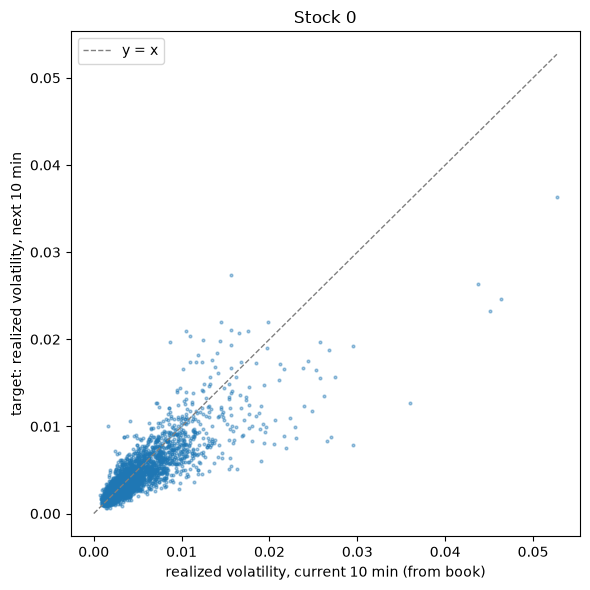

In [5]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(df0["rv"], df0["target"], s=4, alpha=0.4)
lim = [0, max(df0["rv"].max(), df0["target"].max())]
ax.plot(lim, lim, color="grey", lw=1, ls="--", label="y = x")
ax.set_xlabel("realized volatility, current 10 min (from book)")
ax.set_ylabel("target: realized volatility, next 10 min")
ax.set_title("Stock 0")
ax.legend()
fig.tight_layout()
REPORTS.mkdir(exist_ok=True)
fig.savefig(REPORTS / "rv_vs_target_stock0.png", dpi=120)

## Naive baseline over all stocks

In [6]:
rv_all = pd.concat([stock_rv(s) for s in sorted(train["stock_id"].unique())], ignore_index=True)
df = rv_all.merge(train, on=["stock_id", "time_id"], how="inner")
assert len(df) == len(train), "missing (stock_id, time_id) after join"

print(f"stocks: {df['stock_id'].nunique()}, rows: {len(df)}")
print(f"naive RMSPE, all stocks: {rmspe(df['target'].to_numpy(), naive(df)):.4f}")

stocks: 112, rows: 428932
naive RMSPE, all stocks: 0.3414
